# Executable notebook

This notebook is a compact specimen of rendered notebook content. It includes
saved outputs from real Python execution, synthetic data, a DataFrame, two
Seaborn plots, local image includes, and ordinary LaTeX mathematics.

The website stylesheet is loaded by `myst.yml`. This notebook does not require
custom LaTeX macros or per-user JupyterLab settings.

## Notebook setup

The setup uses a fixed random seed so the sample data and figures are
reproducible. The examples run without downloading data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

np.random.seed(42)
np.set_printoptions(legacy="1.25")
sns.set_theme(
    context="notebook",
    style="whitegrid",
    palette=["#287d81", "#b25335"],
)

## Synthetic observations

Suppose we record study time $x_i$ and a score $y_i$ for $n=120$ students.
These are simulated observations for testing the presentation of a book;
they are not evidence about an educational intervention.

The model used to generate the scores is

$$
Y_i = 50 + 4X_i + \varepsilon_i,
\qquad \varepsilon_i \sim \mathcal{N}(0, 6^2).
$$

In [2]:
n = 120
hours = norm(loc=5, scale=1.4).rvs(size=n)
hours = np.clip(hours, 1, 9)
noise = norm(loc=0, scale=6).rvs(size=n)
score = 50 + 4 * hours + noise

data = pd.DataFrame({"hours": hours, "score": score})
data.head(8).round(2)

,hours,score
0,5.70,77.53
1,4.81,63.77
2,5.91,82.04
3,7.13,70.12
4,4.67,72.21
5,4.67,81.83
6,7.21,72.90
7,6.07,70.90


### Printed output

Check monospace alignment and the spacing between a code cell and its output.

In [3]:
mean_score = data["score"].mean()
std_score = data["score"].std(ddof=1)
se_score = std_score / np.sqrt(n)

print(f"Number of observations: {n}")
print(f"Mean score:             {mean_score:.2f}")
print(f"Sample standard dev.:   {std_score:.2f}")
print(f"Estimated standard err.:{se_score:6.2f}")

Number of observations: 120
Mean score:             70.00
Sample standard dev.:   8.36
Estimated standard err.:  0.76


## Seaborn histogram

This is an actual notebook output. Check its size, spacing, axis labels, and
appearance beside the surrounding page in light and dark modes. Website CSS
does not recolour the pixels of the saved figure.

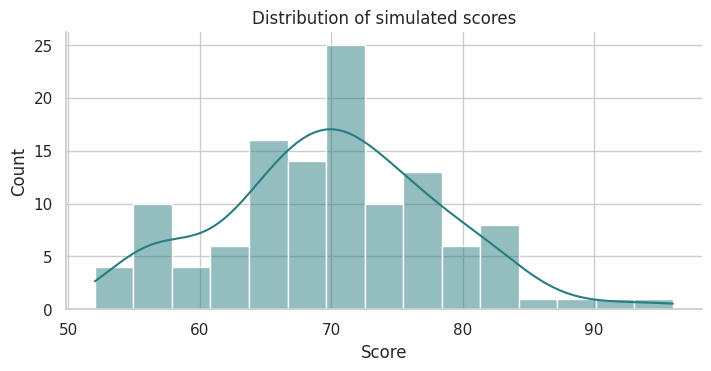

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
sns.histplot(
    data=data,
    x="score",
    bins=15,
    kde=True,
    color="#287d81",
    edgecolor="white",
    ax=ax,
)
ax.set(title="Distribution of simulated scores", xlabel="Score")
sns.despine(ax=ax)
plt.show()

## Seaborn regression plot

The second plot combines points and a fitted line. It deliberately uses no
bootstrap confidence band so the output does not depend on another source
of random variation.

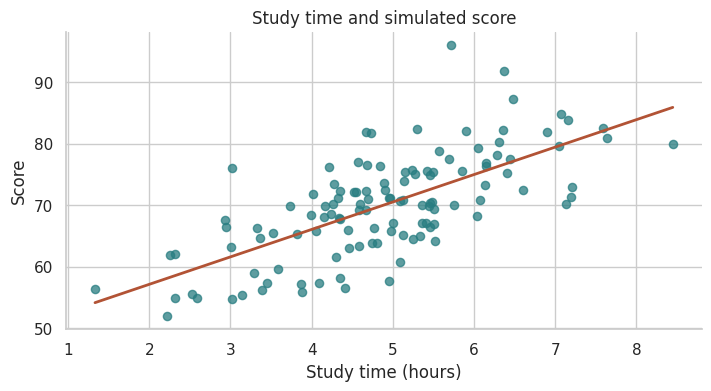

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
sns.regplot(
    data=data,
    x="hours",
    y="score",
    ci=None,
    scatter_kws={"s": 35, "alpha": 0.75, "color": "#287d81"},
    line_kws={"color": "#b25335", "linewidth": 2},
    ax=ax,
)
ax.set(
    title="Study time and simulated score",
    xlabel="Study time (hours)",
    ylabel="Score",
)
sns.despine(ax=ax)
plt.show()

## Local images in notebook Markdown

The same local image can be included in a notebook Markdown cell:

![Standard Normal density with the central interval shaded.](../assets/normal-density.png)

This is a Markdown image include, distinct from the plot outputs above. It
must resolve in the book and when this notebook is opened from the repository.

### A figure directive and caption

```{figure} ../assets/normal-density.png
:label: fig-notebook-density
:alt: Standard Normal density curve with the interval from minus one to plus one shaded.
:width: 70%

A captioned image inside a notebook Markdown cell, with inline math
$\Pr(-1 \leq Z \leq 1) \approx 0.683$.
```

The figure directive is rendered by Jupyter Book. A standard JupyterLab
Markdown renderer will show its source syntax; ordinary Markdown image and
math examples in the surrounding cells remain usable there.

## Inline math and display equations

The sample mean is $\overline{x}$, the sample standard deviation is $s$,
and the estimated standard error is $s/\sqrt{n}$.

$$
\overline{x} = \frac{1}{n} \sum_{i=1}^{n} x_i,
\qquad
s^2 = \frac{1}{n-1} \sum_{i=1}^{n}(x_i-\overline{x})^2.
$$

$$
\begin{aligned}
\operatorname{E}[\overline{X}] &= \mu, \\
\operatorname{Var}(\overline{X}) &= \frac{\sigma^2}{n}.
\end{aligned}
$$

## Markdown table

| Quantity | Notation | Meaning |
| :--- | :---: | :--- |
| Population mean | $\mu$ | The model's mean parameter. |
| Sample mean | $\overline{x}$ | The observed average. |
| Standard error | $\sigma/\sqrt{n}$ | The standard deviation of the sampling distribution of the mean. |

## Code fences inside Markdown

This fence is documentation, rather than an executable cell:

```python
from scipy.stats import norm

rv = norm(loc=0, scale=1)
probability = rv.cdf(1) - rv.cdf(-1)
```

> A quotation inside a notebook should receive the same typography as a
> quotation on the Markdown specimen page.

- A notebook list item with **bold text**.
- Another item with inline code `data.head()`.
- A link back to the [Markdown kitchen sink](markdownpage.md).

## Wide text output

This intentionally long output tests horizontal scrolling without creating
page-wide overflow.

In [6]:
print("A long output line: " + "0123456789_" * 15)

A long output line: 0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_0123456789_


## An admonition inside a notebook

```{note}
The notebook uses the same book-wide CSS as the Markdown page. Test this
note, the page outline, code cells, and captions after each theme change.
```

All code cells in the distributed notebook have been executed successfully.
After editing the examples, use JupyterLab to restart the kernel, run all
cells, and save the notebook before rebuilding the website.